# Machine Learning Assignment 2

## Bagging, Boosting and Bias-Variance on Face Recognition

**Name:** Nishu Kumar
**Roll Number:** P26CS0005

---

### Objective
In this assignment, I compare three models on the **Olivetti Faces** dataset:

1. Single Decision Tree
2. Bagging
3. Boosting (SAMME)

I also check how **robust** each model is, and study its **bias** and **variance**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

import time

In [2]:
seed = 260005
rng = np.random.default_rng(seed)

print("Seed:", seed)

Seed: 260005


In [3]:
faces = fetch_olivetti_faces(shuffle=False)

X = faces.data
y = faces.target

print("Data shape:", X.shape)
print("Labels shape:", y.shape)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /home/nishu-kumar/scikit_learn_data
Data shape: (400, 4096)
Labels shape: (400,)


In [4]:
print("Total images:", len(X))
print("Number of people:", len(np.unique(y)))
print("Images per person:", np.bincount(y)[0])
print("Features per image:", X.shape[1])

Total images: 400
Number of people: 40
Images per person: 10
Features per image: 4096


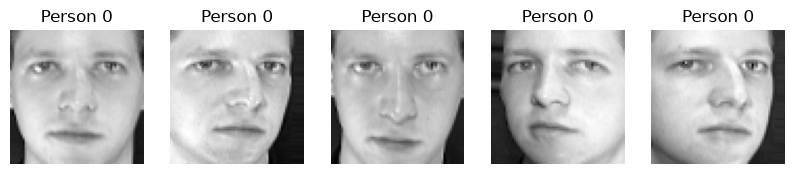

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"Person {y[i]}")
    ax.axis("off")

plt.show()

In [6]:
train_idx = []
val_idx = []
test_idx = []

In [7]:
for person in np.unique(y):
    person_idx = np.where(y == person)[0]
    shuffled = rng.permutation(person_idx)

    train_idx.extend(shuffled[:6])
    val_idx.extend(shuffled[6:8])
    test_idx.extend(shuffled[8:10])

In [8]:
train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

print(len(train_idx), len(val_idx), len(test_idx))

240 80 80


In [9]:
X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [10]:
for person in range(40):
    a = np.sum(y_train == person)
    b = np.sum(y_val == person)
    c = np.sum(y_test == person)

    print(person, a, b, c)

0 6 2 2
1 6 2 2
2 6 2 2
3 6 2 2
4 6 2 2
5 6 2 2
6 6 2 2
7 6 2 2
8 6 2 2
9 6 2 2
10 6 2 2
11 6 2 2
12 6 2 2
13 6 2 2
14 6 2 2
15 6 2 2
16 6 2 2
17 6 2 2
18 6 2 2
19 6 2 2
20 6 2 2
21 6 2 2
22 6 2 2
23 6 2 2
24 6 2 2
25 6 2 2
26 6 2 2
27 6 2 2
28 6 2 2
29 6 2 2
30 6 2 2
31 6 2 2
32 6 2 2
33 6 2 2
34 6 2 2
35 6 2 2
36 6 2 2
37 6 2 2
38 6 2 2
39 6 2 2


In [11]:
np.savez(
    "saved_split.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Split saved.")

Split saved.


In [12]:
X_test_masked = X_test.copy()

masked_images = X_test_masked.reshape(-1, 64, 64)
masked_images[:, 24:40, 24:40] = 0

X_test_masked = masked_images.reshape(-1, 4096)

print("Masked test shape:", X_test_masked.shape)

Masked test shape: (80, 4096)


fig, axes = plt.subplots(1, 2, figsize=(5, 3))

axes[0].imshow(X_test[0].reshape(64, 64), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(X_test_masked[0].reshape(64, 64), cmap="gray")
axes[1].set_title("Masked")
axes[1].axis("off")

plt.show()

## Q1(a) — Decision Tree Baseline
##Train different Decision Tree settings, select the best one using validation accuracy, and report its accuracy and leaf statistics.

In [19]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

print(depth_values)
print(leaf_values)

[2, 4, 8, 16, None]
[1, 2, 4]


In [20]:
tree_results = []

for depth in depth_values:
    for leaf in leaf_values:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=seed
        )

        model.fit(X_train, y_train)

        train_acc = model.score(X_train, y_train)
        val_acc = model.score(X_val, y_val)

        tree_results.append([depth, leaf, train_acc, val_acc])

In [151]:
import pandas as pd

tree_df = pd.DataFrame(
    tree_results,
    columns=["Depth", "Min Leaf", "Train Acc", "Val Acc"]
)
tree_df

,Depth,Rounds,Learners Used,Val Acc
0,1,10,10,0.0500
1,1,25,25,0.0375
2,1,50,50,0.1000
3,1,100,100,0.1375
4,2,10,10,0.0750
5,2,25,25,0.0750
6,2,50,50,0.1375
7,2,100,100,0.1875
8,3,10,10,0.2625
9,3,25,25,0.2375


In [24]:
best_row = tree_df.loc[tree_df["Val Acc"].idxmax()]

best_depth = best_row["Depth"]
if pd.isna(best_depth):
    best_depth = None
else:
    best_depth = int(best_depth)

best_leaf = int(best_row["Min Leaf"])

print("Best depth:", best_depth)
print("Best min leaf:", best_leaf)
print("Best validation accuracy:", best_row["Val Acc"])

Best depth: None
Best min leaf: 4
Best validation accuracy: 0.6375


In [25]:
final_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=seed
)

final_tree.fit(X_train, y_train)

train_acc = final_tree.score(X_train, y_train)
val_acc = final_tree.score(X_val, y_val)
test_acc = final_tree.score(X_test, y_test)

print("Train accuracy:", train_acc)
print("Validation accuracy:", val_acc)
print("Test accuracy:", test_acc)

Train accuracy: 0.975
Validation accuracy: 0.6375
Test accuracy: 0.5875


In [26]:
leaf_ids = final_tree.apply(X_train)

_, counts = np.unique(leaf_ids, return_counts=True)

num_leaves = len(counts)
mean_samples = counts.mean()
single_leaf_fraction = np.mean(counts == 1)

print("Number of leaves:", num_leaves)
print("Mean samples per leaf:", mean_samples)
print("Fraction of single-sample leaves:", single_leaf_fraction)

Number of leaves: 41
Mean samples per leaf: 5.853658536585366
Fraction of single-sample leaves: 0.0


In [27]:
q1a_summary = pd.DataFrame({
    "Metric": [
        "Train Accuracy",
        "Validation Accuracy",
        "Test Accuracy",
        "Number of Leaves",
        "Mean Samples per Leaf",
        "Single-Sample Leaf Fraction"
    ],
    "Value": [
        train_acc,
        val_acc,
        test_acc,
        num_leaves,
        mean_samples,
        single_leaf_fraction
    ]
})

q1a_summary

,Metric,Value
0,Train Accuracy,0.975000
1,Validation Accuracy,0.637500
2,Test Accuracy,0.587500
3,Number of Leaves,41.000000
4,Mean Samples per Leaf,5.853659
5,Single-Sample Leaf Fraction,0.000000


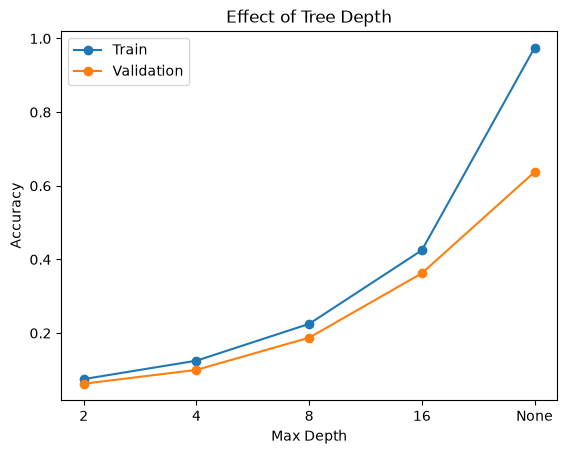

In [28]:
depth_data = tree_df[tree_df["Min Leaf"] == best_leaf].copy()

x = range(len(depth_data))

plt.plot(x, depth_data["Train Acc"], marker="o", label="Train")
plt.plot(x, depth_data["Val Acc"], marker="o", label="Validation")

plt.xticks(x, ["2", "4", "8", "16", "None"])
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth")
plt.legend()
plt.show()

In [30]:
## Q1(b) — Bagging from Scratch
##Build multiple Decision Trees using bootstrap samples of the training set and compare performance for different ensemble sizes.

In [31]:
n_train = len(X_train)

boot_idx = rng.choice(n_train, size=n_train, replace=True)

X_boot = X_train[boot_idx]
y_boot = y_train[boot_idx]

print("Bootstrap size:", len(boot_idx))
print("Unique samples:", len(np.unique(boot_idx)))

Bootstrap size: 240
Unique samples: 156


In [32]:
def make_bootstrap(X_data, y_data):
    idx = rng.choice(len(X_data), size=len(X_data), replace=True)
    return X_data[idx], y_data[idx], idx

In [33]:
X_b, y_b, idx_b = make_bootstrap(X_train, y_train)

print("Sample size:", len(idx_b))
print("Unique samples:", len(np.unique(idx_b)))

Sample size: 240
Unique samples: 150


In [34]:
def train_bagging(B):
    models = []
    boot_indices = []

    for _ in range(B):
        X_b, y_b, idx_b = make_bootstrap(X_train, y_train)

        tree = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            random_state=seed
        )

        tree.fit(X_b, y_b)

        models.append(tree)
        boot_indices.append(idx_b)

    return models, boot_indices

In [35]:
def bagging_predict(models, X_data):
    all_preds = np.array([tree.predict(X_data) for tree in models])

    final_preds = []
    for i in range(X_data.shape[0]):
        votes = np.bincount(all_preds[:, i], minlength=40)
        final_preds.append(np.argmax(votes))

    return np.array(final_preds)

In [36]:
models_1, boot_1 = train_bagging(1)

pred_train = bagging_predict(models_1, X_train)
pred_val = bagging_predict(models_1, X_val)
pred_test = bagging_predict(models_1, X_test)

print("Train accuracy:", accuracy_score(y_train, pred_train))
print("Validation accuracy:", accuracy_score(y_val, pred_val))
print("Test accuracy:", accuracy_score(y_test, pred_test))

Train accuracy: 0.6333333333333333
Validation accuracy: 0.35
Test accuracy: 0.325


In [40]:
B_values = [1, 5, 10, 25, 50, 100, 200]

bag_results = []

for B in B_values:
    models, boot_ids = train_bagging(B)

    train_pred = bagging_predict(models, X_train)
    val_pred = bagging_predict(models, X_val)
    test_pred = bagging_predict(models, X_test)

    train_acc_b = accuracy_score(y_train, train_pred)
    val_acc_b = accuracy_score(y_val, val_pred)
    test_acc_b = accuracy_score(y_test, test_pred)

    unique_avg = np.mean([
        len(np.unique(idx)) for idx in boot_ids
    ])

    bag_results.append(
        [B, train_acc_b, val_acc_b, test_acc_b, unique_avg]
    )

In [39]:
bag_df = pd.DataFrame(
    bag_results,
    columns=["B", "Train Acc", "Val Acc", "Test Acc", "Avg Unique"]
)

print(bag_df)

     B  Train Acc  Val Acc  Test Acc  Avg Unique
0    1   0.725000   0.3500    0.3375     157.000
1    5   0.933333   0.6500    0.4875     152.400
2   10   0.983333   0.7250    0.6625     149.600
3   25   1.000000   0.7750    0.7625     150.320
4   50   1.000000   0.8875    0.7875     151.800
5  100   1.000000   0.8875    0.8875     152.080
6  200   1.000000   0.8875    0.8625     151.785


In [41]:
n = len(X_train)

expected_unique = n * (1 - (1 - 1/n) ** n)

print("Theoretical unique samples:", expected_unique)
print("Observed average:", bag_df["Avg Unique"].mean())

Theoretical unique samples: 151.8931938460841
Observed average: 152.14071428571427


In [43]:
## Q1(c) — OOB Accuracy, Tree Disagreement and Vote Margin
##Measure how the bagged ensemble behaves as the number of trees increases using OOB accuracy, disagreement, and vote margin.

In [46]:
bag_models = {}
bag_boots = {}
oob_results = []

for B in B_values:
    models, boot_ids = train_bagging(B)

    bag_models[B] = models
    bag_boots[B] = boot_ids

    score = oob_accuracy(models, boot_ids)
    oob_results.append(score)

    print(B, score)

1 0.33695652173913043
5 0.3101851851851852
10 0.37916666666666665
25 0.5291666666666667
50 0.6541666666666667
100 0.7416666666666667
200 0.7625


In [47]:
def oob_accuracy(models, boot_ids):
    correct = 0
    used = 0

    for i in range(len(X_train)):
        votes = []

        for tree, idx in zip(models, boot_ids):
            if i not in idx:
                votes.append(tree.predict(X_train[i:i+1])[0])

        if len(votes) > 0:
            pred = np.bincount(votes, minlength=40).argmax()
            correct += (pred == y_train[i])
            used += 1

    return correct / used

In [48]:
def pairwise_disagreement(models, X_data):
    preds = np.array([m.predict(X_data) for m in models])

    scores = []

    for i in range(len(models)):
        for j in range(i + 1, len(models)):
            scores.append(np.mean(preds[i] != preds[j]))

    if len(scores) == 0:
        return 0.0

    return np.mean(scores)

In [49]:
disagreement_results = []

for B in B_values:
    score = pairwise_disagreement(bag_models[B], X_val)
    disagreement_results.append(score)

    print(B, score)

1 0.0
5 0.7725
10 0.7919444444444446
25 0.8007083333333334
50 0.786734693877551
100 0.7945353535353535
200 0.7908423366834171


In [50]:
def mean_vote_margin(models, X_data):
    preds = np.array([m.predict(X_data) for m in models])
    margins = []

    for i in range(len(X_data)):
        votes = np.bincount(preds[:, i], minlength=40)
        top_two = np.sort(votes)[-2:]

        margin = (top_two[-1] - top_two[-2]) / len(models)
        margins.append(margin)

    return np.mean(margins)

In [51]:
margin_results = []

for B in B_values:
    score = mean_vote_margin(bag_models[B], X_val)
    margin_results.append(score)

    print(B, score)

1 1.0
5 0.2625
10 0.22875
25 0.24700000000000003
50 0.264
100 0.25787499999999997
200 0.26975


In [52]:
q1c_df = pd.DataFrame({
    "B": B_values,
    "OOB Acc": oob_results,
    "Disagreement": disagreement_results,
    "Vote Margin": margin_results
})

print(q1c_df)

     B   OOB Acc  Disagreement  Vote Margin
0    1  0.336957      0.000000     1.000000
1    5  0.310185      0.772500     0.262500
2   10  0.379167      0.791944     0.228750
3   25  0.529167      0.800708     0.247000
4   50  0.654167      0.786735     0.264000
5  100  0.741667      0.794535     0.257875
6  200  0.762500      0.790842     0.269750


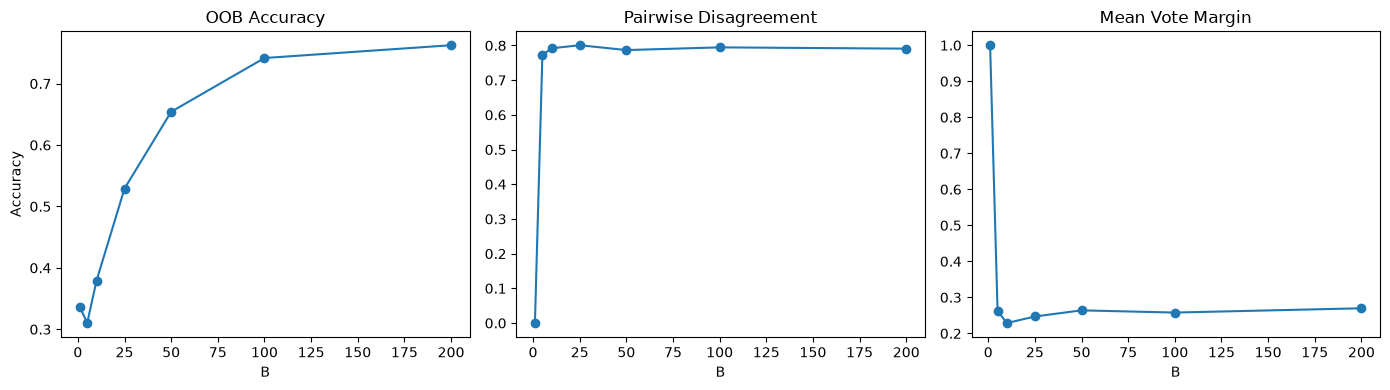

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(B_values, oob_results, marker="o")
axes[0].set_title("OOB Accuracy")
axes[0].set_xlabel("B")
axes[0].set_ylabel("Accuracy")

axes[1].plot(B_values, disagreement_results, marker="o")
axes[1].set_title("Pairwise Disagreement")
axes[1].set_xlabel("B")

axes[2].plot(B_values, margin_results, marker="o")
axes[2].set_title("Mean Vote Margin")
axes[2].set_xlabel("B")

plt.tight_layout()
plt.show()

In [54]:
best_val = bag_df["Val Acc"].max()

best_B = int(
    bag_df[bag_df["Val Acc"] == best_val]["B"].min()
)

print("Final B:", best_B)
print("Validation accuracy:", best_val)

Final B: 50
Validation accuracy: 0.8875


In [55]:
final_bag_models = bag_models[best_B]
final_bag_boots = bag_boots[best_B]

print("Final bagging model uses", len(final_bag_models), "trees")

Final bagging model uses 50 trees


In [57]:
## Q1(d) — Clean vs Masked Test Comparison
##Compare the frozen single tree and final bagging model on clean and masked test faces, including accuracy and confidence.

In [58]:
def bagging_with_confidence(models, X_data):
    preds = np.array([m.predict(X_data) for m in models])

    final_pred = []
    confidence = []

    for i in range(len(X_data)):
        votes = np.bincount(preds[:, i], minlength=40)
        final_pred.append(np.argmax(votes))
        confidence.append(votes.max() / len(models))

    return np.array(final_pred), np.array(confidence)

In [59]:
# single tree
tree_clean_pred = final_tree.predict(X_test)
tree_mask_pred = final_tree.predict(X_test_masked)

tree_clean_conf = final_tree.predict_proba(X_test).max(axis=1).mean()
tree_mask_conf = final_tree.predict_proba(X_test_masked).max(axis=1).mean()

# bagging
bag_clean_pred, bag_clean_conf = bagging_with_confidence(final_bag_models, X_test)
bag_mask_pred, bag_mask_conf = bagging_with_confidence(final_bag_models, X_test_masked)

print("Tree clean:", accuracy_score(y_test, tree_clean_pred), tree_clean_conf)
print("Tree masked:", accuracy_score(y_test, tree_mask_pred), tree_mask_conf)

print("Bagging clean:", accuracy_score(y_test, bag_clean_pred), bag_clean_conf.mean())
print("Bagging masked:", accuracy_score(y_test, bag_mask_pred), bag_mask_conf.mean())

Tree clean: 0.5875 0.9672619047619048
Tree masked: 0.425 0.9875
Bagging clean: 0.85 0.3862500000000001
Bagging masked: 0.5625 0.30025


In [60]:
fixed_idx = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred == y_test)
)[0]

print("Number of corrected cases:", len(fixed_idx))
print("First two:", fixed_idx[:2])

Number of corrected cases: 23
First two: [1 5]



Test index: 1
True class: 0
Tree prediction: 7
Bagging prediction: 0
Bagging votes: {np.int64(0): np.int64(13), np.int64(1): np.int64(2), np.int64(3): np.int64(2), np.int64(4): np.int64(1), np.int64(5): np.int64(1), np.int64(6): np.int64(1), np.int64(7): np.int64(13), np.int64(9): np.int64(3), np.int64(10): np.int64(1), np.int64(11): np.int64(1), np.int64(12): np.int64(4), np.int64(15): np.int64(1), np.int64(17): np.int64(5), np.int64(23): np.int64(2)}


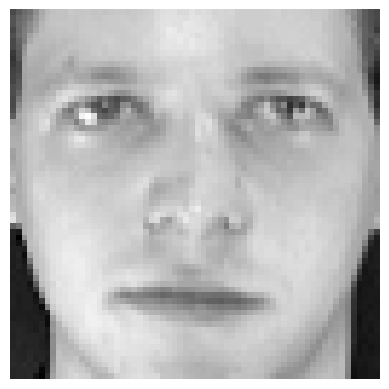


Test index: 5
True class: 2
Tree prediction: 30
Bagging prediction: 2
Bagging votes: {np.int64(0): np.int64(2), np.int64(1): np.int64(3), np.int64(2): np.int64(8), np.int64(3): np.int64(4), np.int64(4): np.int64(1), np.int64(5): np.int64(1), np.int64(9): np.int64(2), np.int64(11): np.int64(2), np.int64(12): np.int64(1), np.int64(13): np.int64(1), np.int64(14): np.int64(1), np.int64(16): np.int64(1), np.int64(17): np.int64(1), np.int64(19): np.int64(1), np.int64(20): np.int64(4), np.int64(21): np.int64(1), np.int64(22): np.int64(1), np.int64(24): np.int64(1), np.int64(25): np.int64(4), np.int64(30): np.int64(2), np.int64(31): np.int64(1), np.int64(34): np.int64(2), np.int64(36): np.int64(2), np.int64(38): np.int64(1), np.int64(39): np.int64(2)}


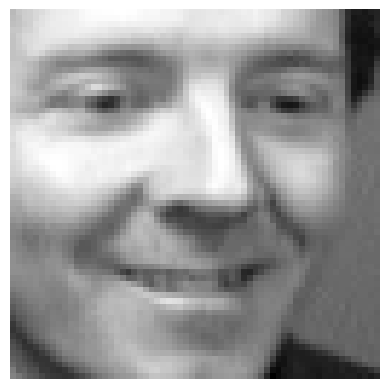

In [61]:
for idx in fixed_idx[:2]:
    votes = np.array([m.predict(X_test[idx:idx+1])[0] for m in final_bag_models])
    classes, counts = np.unique(votes, return_counts=True)

    print("\nTest index:", idx)
    print("True class:", y_test[idx])
    print("Tree prediction:", tree_clean_pred[idx])
    print("Bagging prediction:", bag_clean_pred[idx])
    print("Bagging votes:", dict(zip(classes, counts)))

    plt.imshow(X_test[idx].reshape(64, 64), cmap="gray")
    plt.axis("off")
    plt.show()

In [62]:
both_wrong_idx = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred != y_test)
)[0]

print("Number of cases where both are wrong:", len(both_wrong_idx))
print("First two:", both_wrong_idx[:2])

Number of cases where both are wrong: 10
First two: [0 6]



Test index: 0
True class: 0
Tree prediction: 7
Bagging prediction: 26
Bagging votes: {np.int64(0): np.int64(3), np.int64(3): np.int64(1), np.int64(5): np.int64(2), np.int64(7): np.int64(7), np.int64(8): np.int64(1), np.int64(9): np.int64(2), np.int64(10): np.int64(2), np.int64(12): np.int64(1), np.int64(15): np.int64(10), np.int64(16): np.int64(1), np.int64(17): np.int64(3), np.int64(23): np.int64(3), np.int64(26): np.int64(13), np.int64(39): np.int64(1)}


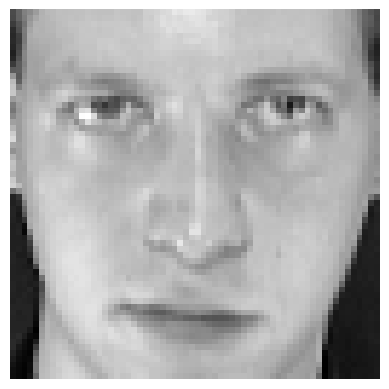


Test index: 6
True class: 3
Tree prediction: 0
Bagging prediction: 39
Bagging votes: {np.int64(0): np.int64(3), np.int64(1): np.int64(1), np.int64(2): np.int64(2), np.int64(3): np.int64(4), np.int64(4): np.int64(5), np.int64(5): np.int64(1), np.int64(7): np.int64(1), np.int64(9): np.int64(1), np.int64(11): np.int64(1), np.int64(12): np.int64(4), np.int64(14): np.int64(4), np.int64(15): np.int64(2), np.int64(16): np.int64(1), np.int64(17): np.int64(6), np.int64(22): np.int64(2), np.int64(28): np.int64(1), np.int64(34): np.int64(1), np.int64(39): np.int64(10)}


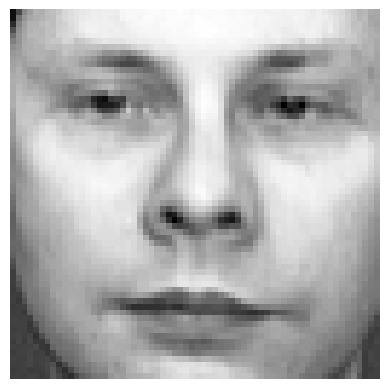

In [63]:
for idx in both_wrong_idx[:2]:
    votes = np.array([m.predict(X_test[idx:idx+1])[0] for m in final_bag_models])
    classes, counts = np.unique(votes, return_counts=True)

    print("\nTest index:", idx)
    print("True class:", y_test[idx])
    print("Tree prediction:", tree_clean_pred[idx])
    print("Bagging prediction:", bag_clean_pred[idx])
    print("Bagging votes:", dict(zip(classes, counts)))

    plt.imshow(X_test[idx].reshape(64, 64), cmap="gray")
    plt.axis("off")
    plt.show()

In [65]:
### Q1(d) Observation
##Bagging improved clean test accuracy from 58.75% to 85.0% and masked accuracy from 42.5% to 56.25%. This shows that combining diverse trees reduces unstable errors, although both models can still fail on difficult or information-lost faces.

In [66]:
X_toy = np.arange(9).reshape(-1, 1)
y_toy = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

K = 3
w = np.ones(len(y_toy)) / len(y_toy)

print("Initial weights:", w)
print("Sum of weights:", w.sum())

Initial weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Sum of weights: 1.0


In [67]:
toy_tree = DecisionTreeClassifier(max_depth=1, random_state=seed)

toy_tree.fit(X_toy, y_toy, sample_weight=w)

toy_pred = toy_tree.predict(X_toy)

print("Predictions:", toy_pred)
print("True labels:", y_toy)

Predictions: [0 0 0 1 1 1 1 1 1]
True labels: [0 0 0 1 1 1 2 2 2]


In [68]:
wrong = (toy_pred != y_toy)

error = np.sum(w[wrong])

print("Wrong predictions:", wrong)
print("Weighted error:", error)

Wrong predictions: [False False False False False False  True  True  True]
Weighted error: 0.3333333333333333


In [69]:
random_error = 1 - 1 / K

if error >= random_error:
    print("Weak learner is not better than random.")
else:
    alpha = np.log((1 - error) / error) + np.log(K - 1)
    print("Alpha:", alpha)

Alpha: 1.3862943611198908


In [70]:
w_new = w * np.exp(alpha * wrong)
w_new = w_new / w_new.sum()

print("Updated weights:", w_new)
print("Sum of weights:", w_new.sum())

Updated weights: [0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]
Sum of weights: 1.0


In [71]:
toy_log = pd.DataFrame({
    "Sample": np.arange(len(y_toy)),
    "True": y_toy,
    "Predicted": toy_pred,
    "Old Weight": w,
    "Wrong": wrong,
    "New Weight": w_new
})

toy_log

,Sample,True,Predicted,Old Weight,Wrong,New Weight
0,0,0,0,0.111111,False,0.055556
1,1,0,0,0.111111,False,0.055556
2,2,0,0,0.111111,False,0.055556
3,3,1,1,0.111111,False,0.055556
4,4,1,1,0.111111,False,0.055556
5,5,1,1,0.111111,False,0.055556
6,6,2,1,0.111111,True,0.222222
7,7,2,1,0.111111,True,0.222222
8,8,2,1,0.111111,True,0.222222


In [73]:
## Q2(b) — SAMME Boosting on Olivetti Faces
##Apply the SAMME boosting algorithm to the face dataset, test the required weak-learner depths and boosting rounds, and select the best model using validation accuracy.

In [75]:
def train_samme(X_data, y_data, depth, rounds):
    n = len(X_data)
    K = len(np.unique(y_data))

    weights = np.ones(n) / n
    models = []
    alphas = []

    for t in range(rounds):
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        tree.fit(X_data, y_data, sample_weight=weights)
        pred = tree.predict(X_data)

        wrong = (pred != y_data)
        error = np.sum(weights[wrong])

        if error >= 1 - 1 / K:
            break

        alpha = np.log((1 - error) / error) + np.log(K - 1)

        weights *= np.exp(alpha * wrong)
        weights /= weights.sum()

        models.append(tree)
        alphas.append(alpha)

    return models, np.array(alphas)

In [76]:
def samme_predict(models, alphas, X_data):
    scores = np.zeros((len(X_data), 40))

    for tree, alpha in zip(models, alphas):
        pred = tree.predict(X_data)
        scores[np.arange(len(X_data)), pred] += alpha

    final_pred = np.argmax(scores, axis=1)

    return final_pred, scores

In [77]:
test_models, test_alphas = train_samme(
    X_train,
    y_train,
    depth=1,
    rounds=10
)

test_pred, test_scores = samme_predict(
    test_models,
    test_alphas,
    X_val
)

print("Learners trained:", len(test_models))
print("Validation accuracy:", accuracy_score(y_val, test_pred))

Learners trained: 10
Validation accuracy: 0.05


In [78]:
boost_results = []

depths = [1, 2, 3, 4]
rounds_list = [10, 25, 50, 100]

for depth in depths:
    for rounds in rounds_list:
        models, alphas = train_samme(
            X_train, y_train,
            depth=depth,
            rounds=rounds
        )

        val_pred, _ = samme_predict(models, alphas, X_val)
        val_acc = accuracy_score(y_val, val_pred)

        boost_results.append(
            [depth, rounds, len(models), val_acc]
        )

In [79]:
boost_df = pd.DataFrame(
    boost_results,
    columns=["Depth", "Rounds", "Learners Used", "Val Acc"]
)

print(boost_df)

    Depth  Rounds  Learners Used  Val Acc
0       1      10             10   0.0500
1       1      25             25   0.0375
2       1      50             50   0.1000
3       1     100            100   0.1375
4       2      10             10   0.0750
5       2      25             25   0.0750
6       2      50             50   0.1375
7       2     100            100   0.1875
8       3      10             10   0.2625
9       3      25             25   0.2375
10      3      50             50   0.3125
11      3     100            100   0.2750
12      4      10             10   0.2250
13      4      25             25   0.4125
14      4      50             50   0.4125
15      4     100            100   0.4250


In [80]:
best_boost_row = boost_df.loc[boost_df["Val Acc"].idxmax()]

best_boost_depth = int(best_boost_row["Depth"])
best_boost_rounds = int(best_boost_row["Rounds"])

print("Best depth:", best_boost_depth)
print("Best rounds:", best_boost_rounds)
print("Validation accuracy:", best_boost_row["Val Acc"])

Best depth: 4
Best rounds: 100
Validation accuracy: 0.425


In [81]:
def train_samme_log(X_data, y_data, depth, rounds):
    n = len(X_data)
    K = len(np.unique(y_data))
    weights = np.ones(n) / n

    models, alphas = [], []
    errors, max_weights, top10_weights = [], [], []
    weight_history, pred_history = [], []

    for t in range(rounds):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=seed + t)
        tree.fit(X_data, y_data, sample_weight=weights)

        pred = tree.predict(X_data)
        wrong = pred != y_data
        error = np.sum(weights[wrong])

        if error >= 1 - 1 / K:
            break

        alpha = np.log((1 - error) / error) + np.log(K - 1)

        weights *= np.exp(alpha * wrong)
        weights /= weights.sum()

        models.append(tree)
        alphas.append(alpha)
        errors.append(error)
        max_weights.append(weights.max())
        top10_weights.append(np.sort(weights)[-10:].sum())
        weight_history.append(weights.copy())
        pred_history.append(pred.copy())

    return models, np.array(alphas), errors, max_weights, top10_weights, weight_history, pred_history

In [82]:
(
    final_boost_models,
    final_boost_alphas,
    boost_errors,
    boost_max_weights,
    boost_top10_weights,
    boost_weight_history,
    boost_pred_history
) = train_samme_log(
    X_train,
    y_train,
    best_boost_depth,
    best_boost_rounds
)

print("Learners trained:", len(final_boost_models))

Learners trained: 100


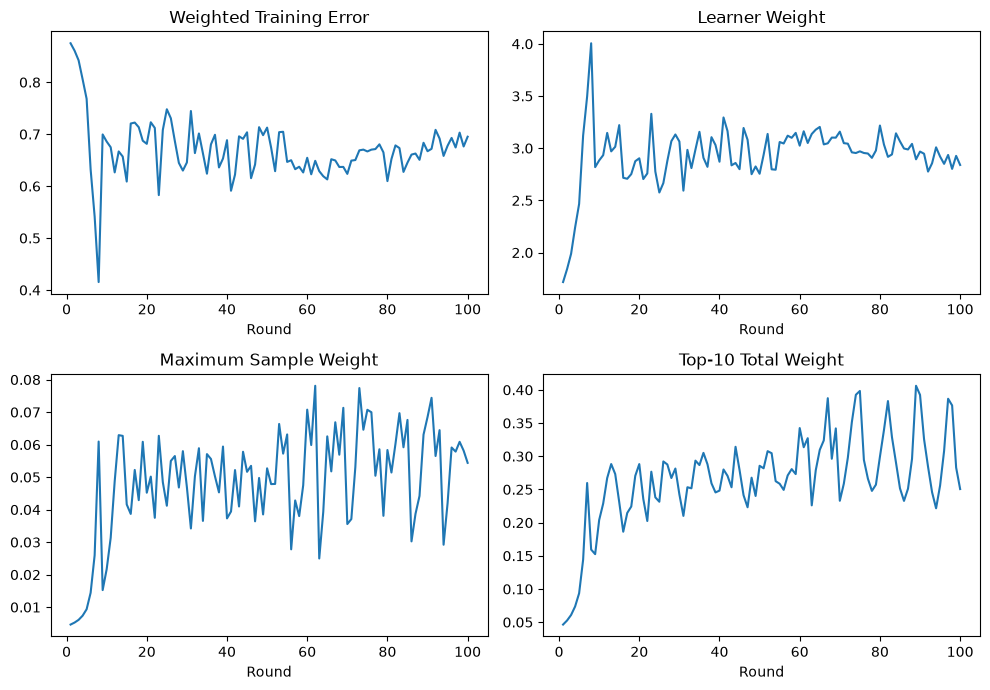

In [83]:
round_ids = np.arange(1, len(final_boost_models) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].plot(round_ids, boost_errors)
axes[0, 0].set_title("Weighted Training Error")
axes[0, 0].set_xlabel("Round")

axes[0, 1].plot(round_ids, final_boost_alphas)
axes[0, 1].set_title("Learner Weight")
axes[0, 1].set_xlabel("Round")

axes[1, 0].plot(round_ids, boost_max_weights)
axes[1, 0].set_title("Maximum Sample Weight")
axes[1, 0].set_xlabel("Round")

axes[1, 1].plot(round_ids, boost_top10_weights)
axes[1, 1].set_title("Top-10 Total Weight")
axes[1, 1].set_xlabel("Round")

plt.tight_layout()
plt.show()

In [85]:
## Q2(c) — Bagging vs Boosting
##Compare bagging and SAMME boosting using 25, 50, and 100 learners based on accuracy and training time.

In [86]:
compare_results = []

for B in [25, 50, 100]:

    start = time.time()
    bag_models, _ = train_bagging(B)
    bag_time = time.time() - start

    bag_train = accuracy_score(y_train, bagging_predict(bag_models, X_train))
    bag_val = accuracy_score(y_val, bagging_predict(bag_models, X_val))
    bag_test = accuracy_score(y_test, bagging_predict(bag_models, X_test))

    start = time.time()
    boost_models, boost_alphas = train_samme(
        X_train, y_train,
        best_boost_depth, B
    )
    boost_time = time.time() - start

    boost_train, _ = samme_predict(boost_models, boost_alphas, X_train)
    boost_val, _ = samme_predict(boost_models, boost_alphas, X_val)
    boost_test, _ = samme_predict(boost_models, boost_alphas, X_test)

    compare_results.append([
        B,
        bag_train, bag_val, bag_test, bag_time,
        accuracy_score(y_train, boost_train),
        accuracy_score(y_val, boost_val),
        accuracy_score(y_test, boost_test),
        boost_time
    ])

In [87]:
compare_df = pd.DataFrame(
    compare_results,
    columns=[
        "B",
        "Bag Train", "Bag Val", "Bag Test", "Bag Time",
        "Boost Train", "Boost Val", "Boost Test", "Boost Time"
    ]
)

print(compare_df)

     B  Bag Train  Bag Val  Bag Test   Bag Time  Boost Train  Boost Val  \
0   25        1.0   0.7875    0.8000  16.970964     0.741667     0.4125   
1   50        1.0   0.8000    0.8125  33.750151     0.841667     0.4125   
2  100        1.0   0.8500    0.8625  68.001129     0.979167     0.4250   

   Boost Test  Boost Time  
0      0.2500    5.223593  
1      0.2625   10.505235  
2      0.3250   21.041757  


Training index: 219
True class: 36
Final sample weight: 0.0543993729462148


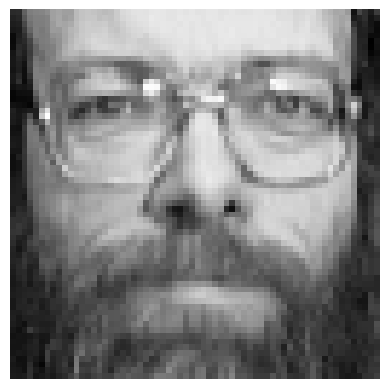

In [88]:
last_weights = boost_weight_history[-1]

hard_idx = np.argmax(last_weights)

print("Training index:", hard_idx)
print("True class:", y_train[hard_idx])
print("Final sample weight:", last_weights[hard_idx])

plt.imshow(X_train[hard_idx].reshape(64, 64), cmap="gray")
plt.axis("off")
plt.show()

In [89]:
history = np.array([
    pred[hard_idx] for pred in boost_pred_history
])

correct_history = history == y_train[hard_idx]

print("True class:", y_train[hard_idx])
print("Wrong rounds:", np.sum(~correct_history))
print("Correct rounds:", np.sum(correct_history))
print("Prediction history:", history)

True class: 36
Wrong rounds: 88
Correct rounds: 12
Prediction history: [ 0 36  2  3  4 12 30 29  1  3  4 12 16 36 39 20 32 22  4 27 14 36 25 20
 22 28  3  4 14 36 24 20 37 28  3 30  4 36  6 17 20  7 23 15  4 36 16 39
 20 37  3  5 34 12 36 39 20 37  4 34 12  3 36 20  1  4 27 34 22 36 20 37
  4  3 11 14 36 39 20 26  4 25 34 22 36 20 17 26  4 25 15 14 36 20 17  3
  4  9 34 14]


In [91]:
## Q2(d) — Clean vs Masked Comparison
##Evaluate the frozen single tree, final bagging model, and selected boosting model on both clean and masked test sets, then compare accuracy and confidence.

In [92]:
def samme_with_confidence(models, alphas, X_data):
    pred, scores = samme_predict(models, alphas, X_data)

    total_alpha = np.sum(alphas)
    norm_scores = scores / total_alpha

    confidence = norm_scores.max(axis=1)

    return pred, confidence

In [93]:
# tree
tree_clean_pred = final_tree.predict(X_test)
tree_mask_pred = final_tree.predict(X_test_masked)

tree_clean_conf = final_tree.predict_proba(X_test).max(axis=1).mean()
tree_mask_conf = final_tree.predict_proba(X_test_masked).max(axis=1).mean()

# bagging
bag_clean_pred, bag_clean_conf = bagging_with_confidence(final_bag_models, X_test)
bag_mask_pred, bag_mask_conf = bagging_with_confidence(final_bag_models, X_test_masked)

# boosting
boost_clean_pred, boost_clean_conf = samme_with_confidence(
    final_boost_models, final_boost_alphas, X_test
)

boost_mask_pred, boost_mask_conf = samme_with_confidence(
    final_boost_models, final_boost_alphas, X_test_masked
)

print("Tree clean:", accuracy_score(y_test, tree_clean_pred), tree_clean_conf)
print("Tree masked:", accuracy_score(y_test, tree_mask_pred), tree_mask_conf)

print("Bag clean:", accuracy_score(y_test, bag_clean_pred), bag_clean_conf.mean())
print("Bag masked:", accuracy_score(y_test, bag_mask_pred), bag_mask_conf.mean())

print("Boost clean:", accuracy_score(y_test, boost_clean_pred), boost_clean_conf.mean())
print("Boost masked:", accuracy_score(y_test, boost_mask_pred), boost_mask_conf.mean())

Tree clean: 0.5875 0.9672619047619048
Tree masked: 0.425 0.9875
Bag clean: 0.85 0.3862500000000001
Bag masked: 0.5625 0.30025
Boost clean: 0.325 0.12063213555243321
Boost masked: 0.225 0.11782225747985717


In [94]:
different_idx = []

for i in range(len(y_test)):
    bag_changed = bag_clean_pred[i] != bag_mask_pred[i]
    boost_changed = boost_clean_pred[i] != boost_mask_pred[i]

    if bag_changed != boost_changed:
        different_idx.append(i)

print("Suitable cases:", different_idx[:10])

Suitable cases: [1, 2, 4, 5, 6, 7, 11, 12, 14, 16]


Test index: 1
True class: 0
Bag clean: 0
Bag masked: 7
Boost clean: 12
Boost masked: 12


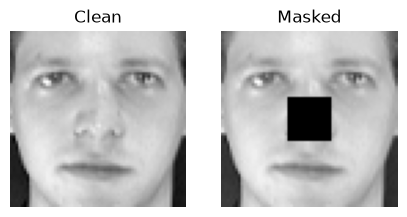

In [95]:
idx = different_idx[0]

print("Test index:", idx)
print("True class:", y_test[idx])

print("Bag clean:", bag_clean_pred[idx])
print("Bag masked:", bag_mask_pred[idx])

print("Boost clean:", boost_clean_pred[idx])
print("Boost masked:", boost_mask_pred[idx])

fig, axes = plt.subplots(1, 2, figsize=(5, 3))

axes[0].imshow(X_test[idx].reshape(64, 64), cmap="gray")
axes[0].set_title("Clean")
axes[0].axis("off")

axes[1].imshow(X_test_masked[idx].reshape(64, 64), cmap="gray")
axes[1].set_title("Masked")
axes[1].axis("off")

plt.show()

In [96]:
# bagging tree predictions
bag_clean_votes = np.array([
    m.predict(X_test[idx:idx+1])[0] for m in final_bag_models
])

bag_mask_votes = np.array([
    m.predict(X_test_masked[idx:idx+1])[0] for m in final_bag_models
])

def one_face_disagreement(votes):
    pairs = []
    for i in range(len(votes)):
        for j in range(i + 1, len(votes)):
            pairs.append(votes[i] != votes[j])
    return np.mean(pairs)

print("Bag disagreement clean:", one_face_disagreement(bag_clean_votes))
print("Bag disagreement masked:", one_face_disagreement(bag_mask_votes))


# boosting weighted scores
_, boost_clean_scores = samme_predict(
    final_boost_models, final_boost_alphas, X_test[idx:idx+1]
)

_, boost_mask_scores = samme_predict(
    final_boost_models, final_boost_alphas, X_test_masked[idx:idx+1]
)

print("Boost top clean class:", np.argmax(boost_clean_scores[0]))
print("Boost top masked class:", np.argmax(boost_mask_scores[0]))

Bag disagreement clean: 0.8546938775510204
Bag disagreement masked: 0.9175510204081633
Boost top clean class: 12
Boost top masked class: 12


In [98]:
### Q2(d) Observation
##Masking increased bagging disagreement from 0.855 to 0.918, showing that the missing region made the individual trees less consistent. In contrast, boosting kept the same top weighted class, so its final decision was less affected for this example.

In [99]:
## Q3(a) — Measured Bias and Variance
##Create 30 resampled training sets, refit the frozen tree, bagging, and boosting models, then measure bias², variance, mean test accuracy, and accuracy standard deviation.

In [100]:
def resample_train():
    new_idx = []

    for person in range(40):
        person_idx = np.where(y_train == person)[0]
        chosen = rng.choice(person_idx, size=6, replace=True)
        new_idx.extend(chosen)

    new_idx = np.array(new_idx)

    return X_train[new_idx], y_train[new_idx]

In [101]:
X_r, y_r = resample_train()

print("Resampled shape:", X_r.shape)

for person in range(40):
    print(person, np.sum(y_r == person))

Resampled shape: (240, 4096)
0 6
1 6
2 6
3 6
4 6
5 6
6 6
7 6
8 6
9 6
10 6
11 6
12 6
13 6
14 6
15 6
16 6
17 6
18 6
19 6
20 6
21 6
22 6
23 6
24 6
25 6
26 6
27 6
28 6
29 6
30 6
31 6
32 6
33 6
34 6
35 6
36 6
37 6
38 6
39 6


In [102]:
def tree_vectors(model, X_data):
    return model.predict_proba(X_data)


def bag_vectors(models, X_data):
    preds = np.array([m.predict(X_data) for m in models])
    out = np.zeros((len(X_data), 40))

    for i in range(len(X_data)):
        out[i] = np.bincount(preds[:, i], minlength=40) / len(models)

    return out


def boost_vectors(models, alphas, X_data):
    _, scores = samme_predict(models, alphas, X_data)
    return scores / alphas.sum()

In [103]:
target_vectors = np.zeros((len(y_test), 40))

target_vectors[
    np.arange(len(y_test)),
    y_test
] = 1

print(target_vectors.shape)

(80, 40)


In [104]:
def train_bagging_data(X_data, y_data, B):
    models = []

    for _ in range(B):
        idx = rng.choice(len(X_data), len(X_data), replace=True)

        tree = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_leaf,
            random_state=seed
        )

        tree.fit(X_data[idx], y_data[idx])
        models.append(tree)

    return models

In [105]:
tree_vecs, bag_vecs, boost_vecs = [], [], []
tree_accs, bag_accs, boost_accs = [], [], []

for r in range(30):
    X_r, y_r = resample_train()

    # single tree
    tree_r = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=seed + r
    )
    tree_r.fit(X_r, y_r)

    tv = tree_vectors(tree_r, X_test)
    tree_vecs.append(tv)
    tree_accs.append(accuracy_score(y_test, np.argmax(tv, axis=1)))

    # bagging
    bag_r = train_bagging_data(X_r, y_r, best_B)

    bv = bag_vectors(bag_r, X_test)
    bag_vecs.append(bv)
    bag_accs.append(accuracy_score(y_test, np.argmax(bv, axis=1)))

    # boosting
    boost_r, alpha_r = train_samme(
        X_r, y_r,
        best_boost_depth,
        best_boost_rounds
    )

    sv = boost_vectors(boost_r, alpha_r, X_test)
    boost_vecs.append(sv)
    boost_accs.append(accuracy_score(y_test, np.argmax(sv, axis=1)))

    print("Finished:", r + 1, "/ 30")

Finished: 1 / 30
Finished: 2 / 30
Finished: 3 / 30
Finished: 4 / 30
Finished: 5 / 30
Finished: 6 / 30
Finished: 7 / 30
Finished: 8 / 30
Finished: 9 / 30
Finished: 10 / 30
Finished: 11 / 30
Finished: 12 / 30
Finished: 13 / 30
Finished: 14 / 30
Finished: 15 / 30
Finished: 16 / 30
Finished: 17 / 30
Finished: 18 / 30
Finished: 19 / 30
Finished: 20 / 30
Finished: 21 / 30
Finished: 22 / 30
Finished: 23 / 30
Finished: 24 / 30
Finished: 25 / 30
Finished: 26 / 30
Finished: 27 / 30
Finished: 28 / 30
Finished: 29 / 30
Finished: 30 / 30


In [106]:
def bias_variance(pred_vectors):
    P = np.array(pred_vectors)          # shape: 30 x 80 x 40
    mean_p = P.mean(axis=0)

    bias2 = np.mean(
        np.sum((mean_p - target_vectors) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum((P - mean_p) ** 2, axis=2)
    )

    return bias2, variance


tree_bias, tree_var = bias_variance(tree_vecs)
bag_bias, bag_var = bias_variance(bag_vecs)
boost_bias, boost_var = bias_variance(boost_vecs)

print("Tree   :", tree_bias, tree_var)
print("Bagging:", bag_bias, bag_var)
print("Boost  :", boost_bias, boost_var)

Tree   : 0.3938888888888889 0.6427777777777778
Bagging: 0.5282486333333333 0.032719033333333335
Boost  : 0.8920107301744205 0.016910355484630386


In [107]:
print("Tree mean acc:", np.mean(tree_accs))
print("Tree std acc :", np.std(tree_accs))

print("Bag mean acc :", np.mean(bag_accs))
print("Bag std acc  :", np.std(bag_accs))

print("Boost mean acc:", np.mean(boost_accs))
print("Boost std acc :", np.std(boost_accs))

Tree mean acc: 0.48166666666666663
Tree std acc : 0.04515405728048023
Bag mean acc : 0.7245833333333332
Bag std acc  : 0.03299042369469594
Boost mean acc: 0.27125000000000005
Boost std acc : 0.08286220992306043


In [108]:
q3a_df = pd.DataFrame({
    "Model": ["Single Tree", "Bagging", "Boosting"],
    "Bias^2": [tree_bias, bag_bias, boost_bias],
    "Variance": [tree_var, bag_var, boost_var],
    "Mean Test Acc": [
        np.mean(tree_accs),
        np.mean(bag_accs),
        np.mean(boost_accs)
    ],
    "Std Test Acc": [
        np.std(tree_accs),
        np.std(bag_accs),
        np.std(boost_accs)
    ]
})

print(q3a_df)

         Model    Bias^2  Variance  Mean Test Acc  Std Test Acc
0  Single Tree  0.393889  0.642778       0.481667      0.045154
1      Bagging  0.528249  0.032719       0.724583      0.032990
2     Boosting  0.892011  0.016910       0.271250      0.082862


In [109]:
## Q3(b) — Effect of Tree Depth on Bias and Variance
##Compare shallow, selected, and deep trees with their 100-tree bagged ensembles to measure how depth affects bias and variance.

In [110]:
print("Selected max_depth:", best_depth)
print("Actual fitted depth:", final_tree.get_depth())

Selected max_depth: None
Actual fitted depth: 34


In [111]:
selected_depth = best_depth if best_depth is not None else final_tree.get_depth()

shallow_depth = 2
deep_depth = max(16, selected_depth + 8)

depth_set = [shallow_depth, selected_depth, deep_depth]

print("Shallow depth :", shallow_depth)
print("Selected depth:", selected_depth)
print("Deep depth    :", deep_depth)

Shallow depth : 2
Selected depth: 34
Deep depth    : 42


In [120]:
depth_results = []

for depth in depth_set:
    single_vecs = []
    bag100_vecs = []
    single_accs = []
    bag100_accs = []

    for r in range(30):
        X_r, y_r = resample_train()

        # single tree
        tree_r = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=seed + r
        )
        tree_r.fit(X_r, y_r)

        tv = tree_vectors(tree_r, X_test)
        single_vecs.append(tv)
        single_accs.append(
            accuracy_score(y_test, np.argmax(tv, axis=1))
        )

        # 100-tree bagging
        models = []
        for b in range(100):
            idx = rng.choice(len(X_r), len(X_r), replace=True)

            tree_b = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=best_leaf,
                random_state=seed + r + b
            )

            tree_b.fit(X_r[idx], y_r[idx])
            models.append(tree_b)

        bv = bag_vectors(models, X_test)
        bag100_vecs.append(bv)
        bag100_accs.append(
            accuracy_score(y_test, np.argmax(bv, axis=1))
        )

    single_bias, single_var = bias_variance(single_vecs)
    bag_bias, bag_var = bias_variance(bag100_vecs)

    depth_results.append([
        depth,
        single_bias,
        single_var,
        np.mean(single_accs),
        bag_bias,
        bag_var,
        np.mean(bag100_accs)
    ])

    print("Finished depth:", depth)

Finished depth: 2
Finished depth: 34
Finished depth: 42


In [121]:
depth_df = pd.DataFrame(
    depth_results,
    columns=[
        "Depth",
        "Tree Bias^2", "Tree Variance", "Tree Acc",
        "Bag Bias^2", "Bag Variance", "Bag Acc"
    ]
)

depth_df["Variance Removed"] = (
    depth_df["Tree Variance"] - depth_df["Bag Variance"]
)

depth_df["Variance Reduction %"] = (
    depth_df["Variance Removed"] / depth_df["Tree Variance"] * 100
)

print(depth_df)

   Depth  Tree Bias^2  Tree Variance  Tree Acc  Bag Bias^2  Bag Variance  \
0      2     0.922987       0.035197  0.054167    0.932481      0.011773   
1     34     0.412173       0.601098  0.471667    0.523640      0.024160   
2     42     0.386278       0.661222  0.476250    0.529337      0.025587   

    Bag Acc  Variance Removed  Variance Reduction %  
0  0.132083          0.023425             66.552352  
1  0.772083          0.576938             95.980711  
2  0.742083          0.635635             96.130355  


In [122]:
## Q3(c) — Does the Deepest Tree Benefit Most from Bagging?
##Use the measured bias, variance, leaf occupancy, disagreement, and accuracy results to check whether the deepest tree always gains the most from bagging.

In [123]:
depth_df["Accuracy Gain"] = (
    depth_df["Bag Acc"] - depth_df["Tree Acc"]
)

print(
    depth_df[
        ["Depth", "Tree Acc", "Bag Acc", "Accuracy Gain",
         "Tree Variance", "Bag Variance"]
    ]
)

   Depth  Tree Acc   Bag Acc  Accuracy Gain  Tree Variance  Bag Variance
0      2  0.054167  0.132083       0.077917       0.035197      0.011773
1     34  0.471667  0.772083       0.300417       0.601098      0.024160
2     42  0.476250  0.742083       0.265833       0.661222      0.025587


In [124]:
depth_extra = []

for depth in depth_set:

    # single tree leaf occupancy
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_leaf,
        random_state=seed
    )
    tree.fit(X_train, y_train)

    leaf_ids = tree.apply(X_train)
    _, counts = np.unique(leaf_ids, return_counts=True)

    mean_leaf = counts.mean()
    single_leaf_frac = np.mean(counts == 1)

    # 100-tree bagging disagreement
    models = train_bagging_data(X_train, y_train, 100)
    disagree = pairwise_disagreement(models, X_val)

    depth_extra.append([
        depth,
        len(counts),
        mean_leaf,
        single_leaf_frac,
        disagree
    ])

In [125]:
extra_df = pd.DataFrame(
    depth_extra,
    columns=[
        "Depth",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction",
        "Disagreement"
    ]
)

q3c_df = depth_df.merge(extra_df, on="Depth")

print(
    q3c_df[
        [
            "Depth",
            "Accuracy Gain",
            "Tree Bias^2",
            "Tree Variance",
            "Bag Variance",
            "Mean Samples/Leaf",
            "Disagreement"
        ]
    ]
)

   Depth  Accuracy Gain  Tree Bias^2  Tree Variance  Bag Variance  \
0      2       0.077917     0.922987       0.035197      0.011773   
1     34       0.300417     0.412173       0.601098      0.024160   
2     42       0.265833     0.386278       0.661222      0.025587   

   Mean Samples/Leaf  Disagreement  
0          80.000000      0.782275  
1           5.853659      0.790962  
2           5.853659      0.786553  


In [126]:
## Q3(d) — Final Model Comparison
##Compare the selected single tree, bagging, and boosting models using clean accuracy, masked accuracy, bias², and variance, then identify stability and robustness differences.

In [127]:
final_table = pd.DataFrame({
    "Model": ["Single Tree", "Bagging", "Boosting"],

    "Clean Acc": [
        accuracy_score(y_test, tree_clean_pred),
        accuracy_score(y_test, bag_clean_pred),
        accuracy_score(y_test, boost_clean_pred)
    ],

    "Masked Acc": [
        accuracy_score(y_test, tree_mask_pred),
        accuracy_score(y_test, bag_mask_pred),
        accuracy_score(y_test, boost_mask_pred)
    ],

    "Bias^2": [
        tree_bias,
        bag_bias,
        boost_bias
    ],

    "Variance": [
        tree_var,
        bag_var,
        boost_var
    ]
})

print(final_table)

         Model  Clean Acc  Masked Acc    Bias^2  Variance
0  Single Tree     0.5875      0.4250  0.393889  0.642778
1      Bagging     0.8500      0.5625  0.529337  0.025587
2     Boosting     0.3250      0.2250  0.892011  0.016910


In [128]:
### Q3(d) Observation
##Bagging achieved the highest clean and masked test accuracy. The single tree had the highest variance, while boosting had the lowest variance but much lower accuracy. Bagging showed the largest accuracy drop after masking, although it still remained the best-performing model on masked faces. These results show that lower variance does not necessarily give higher test accuracy.

In [129]:
def resample_train_seeded(run_seed):
    local_rng = np.random.default_rng(run_seed)
    new_idx = []

    for person in range(40):
        person_idx = np.where(y_train == person)[0]
        chosen = local_rng.choice(person_idx, size=6, replace=True)
        new_idx.extend(chosen)

    new_idx = np.array(new_idx)

    return X_train[new_idx], y_train[new_idx]

In [130]:
X_r, y_r = resample_train_seeded(seed + r)

In [142]:
from joblib import Parallel, delayed

def fit_one_tree(X_data, y_data, idx, depth, tree_seed):
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_leaf,
        random_state=tree_seed
    )

    tree.fit(X_data[idx], y_data[idx])
    return tree


def train_bagging_seeded(X_data, y_data, B, run_seed, depth):
    local_rng = np.random.default_rng(run_seed)

    boot_indices = [
        local_rng.choice(
            len(X_data),
            size=len(X_data),
            replace=True
        )
        for _ in range(B)
    ]

    models = Parallel(n_jobs=-1)(
        delayed(fit_one_tree)(
            X_data,
            y_data,
            boot_indices[b],
            depth,
            run_seed + b
        )
        for b in range(B)
    )

    return models

In [143]:
depth_results = []

for depth in depth_set:
    tree_runs = []
    bag_runs = []
    tree_acc_runs = []
    bag_acc_runs = []

    for r in range(30):
        run_seed = seed + r
        X_r, y_r = resample_train_seeded(run_seed)

        # single tree
        tree_r = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=run_seed
        )

        tree_r.fit(X_r, y_r)

        tv = tree_vectors(tree_r, X_test)
        tree_runs.append(tv)

        tree_acc_runs.append(
            accuracy_score(y_test, np.argmax(tv, axis=1))
        )

        # 100-tree parallel bagging
        bag_r = train_bagging_seeded(
            X_r,
            y_r,
            100,
            run_seed + 1000,
            depth
        )

        bv = bag_vectors(bag_r, X_test)
        bag_runs.append(bv)

        bag_acc_runs.append(
            accuracy_score(y_test, np.argmax(bv, axis=1))
        )

    tree_b, tree_v = bias_variance(tree_runs)
    bag_b, bag_v = bias_variance(bag_runs)

    depth_results.append([
        depth,
        tree_b,
        tree_v,
        np.mean(tree_acc_runs),
        bag_b,
        bag_v,
        np.mean(bag_acc_runs)
    ])

    print("Finished depth:", depth)

Finished depth: 2
Finished depth: 34
Finished depth: 42


In [144]:
depth_df = pd.DataFrame(
    depth_results,
    columns=[
        "Depth",
        "Tree Bias^2",
        "Tree Variance",
        "Tree Acc",
        "Bag Bias^2",
        "Bag Variance",
        "Bag Acc"
    ]
)

depth_df["Variance Removed"] = (
    depth_df["Tree Variance"] - depth_df["Bag Variance"]
)

depth_df["Variance Reduction %"] = (
    depth_df["Variance Removed"] /
    depth_df["Tree Variance"] * 100
)

depth_df["Accuracy Gain"] = (
    depth_df["Bag Acc"] - depth_df["Tree Acc"]
)

print(depth_df)

   Depth  Tree Bias^2  Tree Variance  Tree Acc  Bag Bias^2  Bag Variance  \
0      2     0.918689       0.035772  0.056250    0.934073      0.011741   
1     34     0.364727       0.608350  0.497500    0.519765      0.024705   
2     42     0.360833       0.630000  0.504583    0.518848      0.024744   

   Bag Acc  Variance Removed  Variance Reduction %  Accuracy Gain  
0   0.1400          0.024031             67.177714       0.083750  
1   0.7700          0.583645             95.939046       0.272500  
2   0.7725          0.605256             96.072370       0.267917  


In [145]:
depth_extra = []

for depth in depth_set:

    # single tree for leaf statistics
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_leaf,
        random_state=seed
    )
    tree.fit(X_train, y_train)

    leaf_ids = tree.apply(X_train)
    _, counts = np.unique(leaf_ids, return_counts=True)

    mean_leaf = counts.mean()
    single_leaf_fraction = np.mean(counts == 1)

    # 100-tree bagging at the same depth
    models = train_bagging_seeded(
        X_train,
        y_train,
        100,
        seed + 5000,
        depth
    )

    disagreement = pairwise_disagreement(models, X_val)

    depth_extra.append([
        depth,
        len(counts),
        mean_leaf,
        single_leaf_fraction,
        disagreement
    ])

    print("Finished depth:", depth)

Finished depth: 2
Finished depth: 34
Finished depth: 42


In [146]:
extra_df = pd.DataFrame(
    depth_extra,
    columns=[
        "Depth",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction",
        "Disagreement"
    ]
)

q3c_df = depth_df.merge(extra_df, on="Depth")

print(
    q3c_df[
        [
            "Depth",
            "Accuracy Gain",
            "Tree Bias^2",
            "Tree Variance",
            "Bag Variance",
            "Mean Samples/Leaf",
            "Single Leaf Fraction",
            "Disagreement"
        ]
    ]
)

   Depth  Accuracy Gain  Tree Bias^2  Tree Variance  Bag Variance  \
0      2       0.083750     0.918689       0.035772      0.011741   
1     34       0.272500     0.364727       0.608350      0.024705   
2     42       0.267917     0.360833       0.630000      0.024744   

   Mean Samples/Leaf  Single Leaf Fraction  Disagreement  
0          80.000000                   0.0      0.960508  
1           5.853659                   0.0      0.793838  
2           5.853659                   0.0      0.793851  


In [147]:
## Q3(c) Observation
##Bagging gave the largest accuracy improvement at depth 34, not at the deepest depth 42. The deeper tree had slightly higher variance, while both depths had almost identical leaf occupancy and disagreement. This shows that the largest variance reduction does not necessarily produce the largest accuracy gain.

In [148]:
final_table = pd.DataFrame({
    "Model": ["Single Tree", "Bagging", "Boosting"],

    "Clean Acc": [
        accuracy_score(y_test, tree_clean_pred),
        accuracy_score(y_test, bag_clean_pred),
        accuracy_score(y_test, boost_clean_pred)
    ],

    "Masked Acc": [
        accuracy_score(y_test, tree_mask_pred),
        accuracy_score(y_test, bag_mask_pred),
        accuracy_score(y_test, boost_mask_pred)
    ],

    "Bias^2": [
        tree_bias,
        bag_bias,
        boost_bias
    ],

    "Variance": [
        tree_var,
        bag_var,
        boost_var
    ]
})

print(final_table)

         Model  Clean Acc  Masked Acc    Bias^2  Variance
0  Single Tree     0.5875      0.4250  0.360833  0.630000
1      Bagging     0.8500      0.5625  0.521381  0.032661
2     Boosting     0.3250      0.2250  0.890451  0.016942


In [149]:
### Q3(d) Observation
##Bagging achieved the highest clean and masked test accuracy. Boosting had the lowest variance, while the single tree had the highest variance and was therefore the least stable. Bagging showed the largest accuracy drop after masking, although it still performed best on the masked test set. The boosting model had very low variance but poor accuracy and high bias, showing that the lowest variance does not necessarily give the best test performance.